<a href="https://colab.research.google.com/github/siyaagarwal2005/sepsis-prediction-using-LSTM/blob/main/1_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook I — Data Exploration

---

**Project:** AI-Based Sepsis Early Warning System  
**Dataset:** PhysioNet Challenge 2019 (pre-merged CSV)  
**Author:** *Siya Agarwal*  
**Date:** *05 March, 2026*

---

### Purpose
Understand the raw dataset before any transformation is applied. This notebook answers four core questions:
1. What is the shape and structure of the data?
2. Which columns have missing values, and how severe is the missingness?
3. Are there any data quality issues (impossible values, duplicates)?
4. What are the basic statistical properties of the selected features?

### Inputs
- `/content/drive/MyDrive/sepsis_project/data/sepsis_dataset.csv` — raw merged dataset

### Outputs
- Printed summaries and plots (no files saved — this is a read-only inspection notebook)

### Next Notebook
- `II_preprocessing.ipynb` — missing value handling, scaling, patient-wise train/test split

---
## Section 0 — Mount Google Drive & Imports

We mount Google Drive to access the dataset stored in our project folder.  
All paths in this project are anchored to `BASE_PATH` so nothing breaks if the folder is moved.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

#Display settings
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted')

# === Project Paths ===
BASE_PATH= '/content/drive/MyDrive/sepsis_project/'
DATA_PATH= BASE_PATH + 'data/sepsis_dataset.csv'

print("Drive mounted. ")
print(f"Data path: {DATA_PATH}")

Drive mounted. 
Data path: /content/drive/MyDrive/sepsis_project/data/sepsis_dataset.csv


---
## Section 1 — Load the Dataset

We load the pre-merged CSV and immediately verify three numbers that should match the dataset spec:
- **~1.55 million rows** — one row per patient-hour
- **~40,336 unique patients** — identified by `Patient_ID`
- **~2,932 septic patients** — where `SepsisLabel` is ever 1


In [ ]:
df = pd.read_csv(DATA_PATH)

# ── Verification against dataset spec ─────────────────────────────────────────
n_patients = df['Patient_ID'].nunique()
n_septic   = df.groupby('Patient_ID')['SepsisLabel'].max().sum()
memory_mb  = df.memory_usage(deep=True).sum() / 1e6

print('=== Dataset Load Summary ===')
print(f'Rows            : {len(df):,}')
print(f'Columns         : {df.shape[1]}')
print(f'Unique patients : {n_patients:,}')
print(f'Septic patients : {int(n_septic):,}')
print(f'Sepsis rate     : {n_septic / n_patients * 100:.2f}%')
print(f'Memory usage    : {memory_mb:.1f} MB')

print('\n=== First 5 Rows ===')
display(df.head())

=== Dataset Load Summary ===
Rows            : 1,552,210
Columns         : 44
Unique patients : 40,336
Septic patients : 2,932
Sepsis rate     : 7.27%
Memory usage    : 546.4 MB

=== First 5 Rows ===


,Unnamed: 0,Hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,EtCO2,BaseExcess,HCO3,FiO2,pH,PaCO2,SaO2,AST,BUN,Alkalinephos,Calcium,Chloride,Creatinine,Bilirubin_direct,Glucose,Lactate,Magnesium,Phosphate,Potassium,Bilirubin_total,TroponinI,Hct,Hgb,PTT,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel,Patient_ID
0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.54,0,NaN,NaN,-0.02,1,0,17072
1,1,1,65.00,100.00,NaN,NaN,72.00,NaN,16.50,NaN,NaN,NaN,0.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.54,0,NaN,NaN,-0.02,2,0,17072
2,2,2,78.00,100.00,NaN,NaN,42.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.54,0,NaN,NaN,-0.02,3,0,17072
3,3,3,73.00,100.00,NaN,NaN,NaN,NaN,17.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.54,0,NaN,NaN,-0.02,4,0,17072
4,4,4,70.00,100.00,NaN,129.00,74.00,69.00,14.00,NaN,NaN,26.00,0.40,NaN,NaN,NaN,NaN,23.00,NaN,9.60,104.00,0.80,NaN,161.00,NaN,1.60,2.10,3.20,NaN,NaN,29.70,9.50,30.60,11.30,NaN,330.00,68.54,0,NaN,NaN,-0.02,5,0,17072


---
## Section 2 — Column Overview

The 44 columns fall into four clinical categories:

| Category | Description | Examples |
|----------|-------------|----------|
| **Vitals** | Measured continuously at the bedside | HR, O2Sat, Temp, SBP |
| **Labs** | Blood/urine tests ordered by clinicians | Lactate, WBC, Creatinine |
| **Demographics** | Patient background, static or slow-changing | Age, Gender, ICULOS |
| **Meta** | Identifiers and target label | Patient_ID, SepsisLabel |

Understanding which category each column belongs to matters later:
- Labs are drawn infrequently — higher missingness is expected, not an error
- Vitals are more complete but still noisy
- `ICULOS` (ICU Length of Stay in hours) is our time axis — not `Hour`

We also drop `Unnamed: 0` and `Hour` which are artefacts of the merge process and are not needed.

In [ ]:
# ── Drop artefact columns if present ──────────────────────────────────────────
cols_to_drop = [c for c in ['Unnamed: 0', 'Hour'] if c in df.columns]
if cols_to_drop:
    df.drop(columns=cols_to_drop, inplace=True)
    print(f'Dropped artefact columns: {cols_to_drop}')
else:
    print('No artefact columns found. No columns dropped.')

# ── Clinical groupings ─────────────────────────────────────────────────────────
VITALS = ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'EtCO2']
LABS   = ['BaseExcess', 'HCO3', 'FiO2', 'pH', 'PaCO2', 'SaO2', 'AST',
          'BUN', 'Alkalinephos', 'Calcium', 'Chloride', 'Creatinine',
          'Bilirubin_direct', 'Glucose', 'Lactate', 'Magnesium', 'Phosphate',
          'Potassium', 'Bilirubin_total', 'TroponinI', 'Hct', 'Hgb',
          'PTT', 'WBC', 'Fibrinogen', 'Platelets']
DEMO   = ['Age', 'Gender', 'Unit1', 'Unit2', 'HospAdmTime', 'ICULOS']
META   = ['Patient_ID', 'SepsisLabel']

# Filter to only columns that exist in this dataframe (defensive check)
VITALS = [c for c in VITALS if c in df.columns]
LABS   = [c for c in LABS   if c in df.columns]
DEMO   = [c for c in DEMO   if c in df.columns]

category_map = ({c: 'Vital' for c in VITALS} |
                {c: 'Lab'   for c in LABS}   |
                {c: 'Demo'  for c in DEMO}   |
                {c: 'Meta'  for c in META})

dtype_summary = pd.DataFrame({
    'dtype'    : df.dtypes,
    'category' : pd.Series(category_map)
})

print(f'Total columns after drop: {df.shape[1]}')
print('\n=== Column Dtype & Category Summary ===')
display(dtype_summary)

Dropped artefact columns: ['Unnamed: 0', 'Hour']
Total columns after drop: 42

=== Column Dtype & Category Summary ===


,dtype,category
AST,float64,Lab
Age,float64,Demo
Alkalinephos,float64,Lab
BUN,float64,Lab
BaseExcess,float64,Lab
Bilirubin_direct,float64,Lab
Bilirubin_total,float64,Lab
Calcium,float64,Lab
Chloride,float64,Lab
Creatinine,float64,Lab


---
## Section 3 — Missingness Analysis

Missingness in ICU data is **not random**. When a clinician orders a lactate test, it's because
they suspect something is wrong. The absence of a result (NaN) can itself be a clinical signal.

Expected missingness by category:
- **Vitals** (~10–30% missing) — measured regularly but sometimes skipped
- **Labs** (~40–95% missing) — only drawn when ordered; some tests are very rare
- **Demographics** (very low missing) — recorded once at admission

Columns above 80% missing will be scrutinised carefully. In preprocessing we will use
forward-fill (LOCF) per patient, followed by median imputation for any remaining NaNs.

In [ ]:
missing = pd.DataFrame({
    'missing_n'  : df.isnull().sum(),
    'missing_pct': df.isnull().mean().mul(100).round(2),
    'dtype'      : df.dtypes,
    'category'   : pd.Series(category_map)
}).sort_values('missing_pct', ascending=False)

print('=== Full Missingness Report ===')
display(missing)

print(f'\nColumns with > 80% missing : {(missing["missing_pct"] > 80).sum()}')
print(f'Columns with > 50% missing : {(missing["missing_pct"] > 50).sum()}')
print(f'Columns with > 0%  missing : {(missing["missing_pct"] > 0).sum()}')
print(f'Columns with 0%    missing : {(missing["missing_pct"] == 0).sum()}')

=== Full Missingness Report ===


,missing_n,missing_pct,dtype,category
Bilirubin_direct,1549220,99.81,float64,Lab
Fibrinogen,1541968,99.34,float64,Lab
TroponinI,1537429,99.05,float64,Lab
Bilirubin_total,1529069,98.51,float64,Lab
Alkalinephos,1527269,98.39,float64,Lab
AST,1527027,98.38,float64,Lab
Lactate,1510764,97.33,float64,Lab
PTT,1506511,97.06,float64,Lab
SaO2,1498649,96.55,float64,Lab
EtCO2,1494574,96.29,float64,Vital



Columns with > 80% missing : 27
Columns with > 50% missing : 28
Columns with > 0%  missing : 36
Columns with 0%    missing : 6


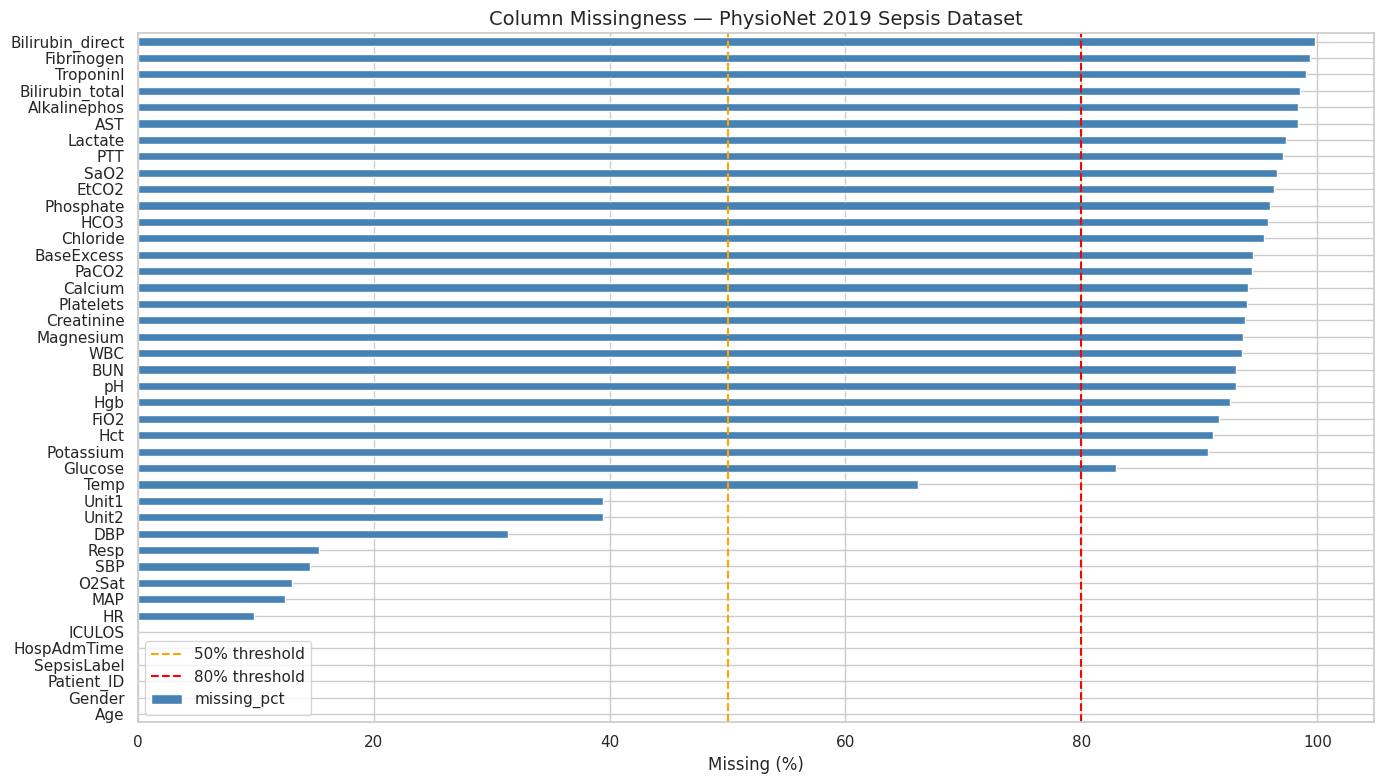

In [ ]:
# ── Missingness bar chart ──────────────────────────────────────────────────────
# Sorted ascending so the most-missing columns appear at the top.
# Dashed lines mark the 50% and 80% drop-consideration thresholds.
fig, ax = plt.subplots(figsize=(14, 8))

cols_sorted = missing.sort_values('missing_pct', ascending=True).index
missing.loc[cols_sorted, 'missing_pct'].plot(
    kind='barh', ax=ax, color='steelblue', edgecolor='white'
)

ax.axvline(50, color='orange', linestyle='--', linewidth=1.5, label='50% threshold')
ax.axvline(80, color='red',    linestyle='--', linewidth=1.5, label='80% threshold')
ax.set_xlabel('Missing (%)', fontsize=12)
ax.set_title('Column Missingness — PhysioNet 2019 Sepsis Dataset', fontsize=14)
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## Section 4 — Descriptive Statistics

We compute `.describe()` per clinical category to keep output readable.

Key things to watch for:
- **Min/max outliers** — HR of 0 or 300 bpm is physiologically impossible
- **Skewed distributions** — Lactate and Creatinine are right-skewed; may need log transform
- **Scale differences** — Age (20-100 years) VS ICULOS (1-336 hours).
  StandardScaler in preprocessing will normalise these to zero mean and unit variance.

In [ ]:
print('=== Vitals — Descriptive Statistics ===')
display(df[VITALS].describe().T.round(2))

print('\n=== Labs — Descriptive Statistics (first half) ===')
display(df[LABS[:13]].describe().T.round(2))

print('\n=== Labs — Descriptive Statistics (second half) ===')
display(df[LABS[13:]].describe().T.round(2))

print('\n=== Demographics — Descriptive Statistics ===')
display(df[DEMO].describe().T.round(2))

=== Vitals — Descriptive Statistics ===


,count,mean,std,min,25%,50%,75%,max
HR,1398811.00,84.58,17.33,20.00,72.00,83.50,95.50,280.00
O2Sat,1349474.00,97.19,2.94,20.00,96.00,98.00,99.50,100.00
Temp,525226.00,36.98,0.77,20.90,36.50,37.00,37.50,50.00
SBP,1325945.00,123.75,23.23,20.00,107.00,121.00,138.00,300.00
MAP,1358940.00,82.40,16.34,20.00,71.00,80.00,92.00,300.00
DBP,1065656.00,63.83,13.96,20.00,54.00,62.00,72.00,300.00
Resp,1313875.00,18.73,5.10,1.00,15.00,18.00,21.50,100.00
EtCO2,57636.00,32.96,7.95,10.00,28.00,33.00,38.00,100.00



=== Labs — Descriptive Statistics (first half) ===


,count,mean,std,min,25%,50%,75%,max
BaseExcess,84145.00,-0.69,4.29,-32.00,-3.00,0.00,1.00,100.00
HCO3,65028.00,24.08,4.38,0.00,22.00,24.00,26.80,55.00
FiO2,129365.00,0.55,11.12,-50.00,0.40,0.50,0.60,4000.00
pH,107573.00,7.38,0.07,6.62,7.34,7.38,7.43,7.93
PaCO2,86301.00,41.02,9.27,10.00,35.00,40.00,45.00,100.00
SaO2,53561.00,92.65,10.89,23.00,94.00,97.00,98.00,100.00
AST,25183.00,260.22,855.75,3.00,22.00,41.00,111.00,9961.00
BUN,106568.00,23.92,19.99,1.00,12.00,17.00,28.00,268.00
Alkalinephos,24941.00,102.48,120.12,7.00,54.00,74.00,108.00,3833.00
Calcium,91331.00,7.56,2.43,1.00,7.70,8.30,8.70,27.90



=== Labs — Descriptive Statistics (second half) ===


,count,mean,std,min,25%,50%,75%,max
Glucose,265516.00,136.93,51.31,10.00,106.00,127.00,153.00,988.00
Lactate,41446.00,2.65,2.53,0.20,1.26,1.80,3.00,31.00
Magnesium,97951.00,2.05,0.40,0.20,1.80,2.00,2.20,9.80
Phosphate,62301.00,3.54,1.42,0.20,2.60,3.30,4.10,18.80
Potassium,144525.00,4.14,0.64,1.00,3.70,4.10,4.40,27.50
Bilirubin_total,23141.00,2.11,4.31,0.10,0.50,0.90,1.70,49.60
TroponinI,14781.00,8.29,24.81,0.01,0.04,0.30,3.98,440.00
Hct,137433.00,30.79,5.49,5.50,27.00,30.30,34.10,71.70
Hgb,114591.00,10.43,1.97,2.20,9.10,10.30,11.70,32.00
PTT,45699.00,41.23,26.22,12.50,27.80,32.40,42.80,250.00



=== Demographics — Descriptive Statistics ===


,count,mean,std,min,25%,50%,75%,max
Age,1552210.00,62.01,16.39,14.00,51.68,64.00,74.00,100.00
Gender,1552210.00,0.56,0.50,0.00,0.00,1.00,1.00,1.00
Unit1,940250.00,0.50,0.50,0.00,0.00,0.00,1.00,1.00
Unit2,940250.00,0.50,0.50,0.00,0.00,1.00,1.00,1.00
HospAdmTime,1552202.00,-56.13,162.26,-5366.86,-47.05,-6.03,-0.04,23.99
ICULOS,1552210.00,26.99,29.01,1.00,11.00,21.00,34.00,336.00


---
## Section 5 — Sanity Checks

Before any modeling, we verify the data does not contain obvious errors that would silently
corrupt downstream steps. These checks are fast and can save hours of debugging later.

Checks performed:
1. `SepsisLabel` — must only contain 0 and 1
2. `HR` — must be positive (a negative heart rate is physically meaningless)
3. `Temp` — must be in a plausible Celsius range (25–45°C)
4. `O2Sat` — oxygen saturation must be within 0–100%
5. `ICULOS` — time axis; must be positive integers
6. Duplicate rows — a sign of merge errors
7. Rows per patient — every patient should have at least 1 row

In [ ]:
print('=== Sanity Check Results ===')

# 1. SepsisLabel should only be 0 or 1
label_vals = sorted(df['SepsisLabel'].dropna().unique().tolist())
print(f'SepsisLabel unique values     : {label_vals}')        # expect [0, 1]

# 2. Heart rate must be positive
hr_neg = (df['HR'] < 0).sum()
print(f'HR < 0 (impossible)           : {hr_neg}')            # expect 0

# 3. Temperature out of clinical range (Celsius)
temp_bad = ((df['Temp'] < 25) | (df['Temp'] > 45)).sum()
print(f'Temp outside 25–45 C          : {temp_bad}')          # expect 0 or very few

# 4. O2Sat must be 0–100%
o2_bad = ((df['O2Sat'] < 0) | (df['O2Sat'] > 100)).sum()
print(f'O2Sat outside 0–100%          : {o2_bad}')            # expect 0 or very few

# 5. ICULOS range
print(f'ICULOS min / max              : {df["ICULOS"].min()} / {df["ICULOS"].max()}')  # expect 1 / ~336

# 6. Duplicate rows (suggests a merge error)
dupe_count = df.duplicated().sum()
print(f'Duplicate rows                : {dupe_count}')        # expect 0

# 7. Rows per patient (every patient must have at least 1 ICU hour)
rows_per_patient = df.groupby('Patient_ID').size()
print(f'Min rows per patient          : {rows_per_patient.min()}')
print(f'Max rows per patient          : {rows_per_patient.max()}')
print(f'Median rows per patient       : {rows_per_patient.median()}')

=== Sanity Check Results ===
SepsisLabel unique values     : [0, 1]
HR < 0 (impossible)           : 0
Temp outside 25–45 C          : 6
O2Sat outside 0–100%          : 0
ICULOS min / max              : 1 / 336
Duplicate rows                : 0
Min rows per patient          : 8
Max rows per patient          : 336
Median rows per patient       : 38.0


---
## Section 6 — Selected Features Confirmation

Based on clinical relevance and dataset coverage, the following 17 columns are selected
for all downstream notebooks. This selection balances predictive power with data availability.

| Feature | Type | Clinical Role |
|---------|------|---------------|
| `HR` | Vital | Heart rate — tachycardia is a sepsis criterion |
| `O2Sat` | Vital | Oxygen saturation — drops in sepsis |
| `Temp` | Vital | Temperature — fever/hypothermia are SIRS criteria |
| `SBP` | Vital | Systolic BP — hypotension indicates septic shock |
| `MAP` | Vital | Mean arterial pressure — key perfusion indicator |
| `DBP` | Vital | Diastolic BP — supports MAP assessment |
| `Resp` | Vital | Respiratory rate — elevated in SIRS |
| `Lactate` | Lab | Tissue hypoperfusion marker — direct sepsis indicator |
| `WBC` | Lab | White blood cell count — immune response |
| `Creatinine` | Lab | Kidney function — organ failure marker |
| `BUN` | Lab | Blood urea nitrogen — kidney stress |
| `pH` | Lab | Acid-base balance — acidosis in sepsis |
| `Age` | Demo | Risk factor |
| `Gender` | Demo | Risk factor |
| `ICULOS` | Demo | Time axis — hours since ICU admission |
| `Patient_ID` | Meta | Patient identifier — used for grouping, never as a feature |
| `SepsisLabel` | Meta | Target variable (0 = no sepsis, 1 = sepsis onset) |

In [ ]:
SELECTED_FEATURES = [
    'HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp',
    'Lactate', 'WBC', 'Creatinine', 'BUN', 'pH',
    'Age', 'Gender', 'ICULOS',
    'Patient_ID', 'SepsisLabel'
]

# ── Verify all selected columns are present ────────────────────────────────────
missing_cols = [c for c in SELECTED_FEATURES if c not in df.columns]
if missing_cols:
    print(f'WARNING — Missing selected columns: {missing_cols}')
else:
    print('All 17 selected features confirmed present in the dataset.')

# ── Missingness for selected features only ─────────────────────────────────────
print('\n=== Missingness for Selected Features ===')
sel_missing = (df[SELECTED_FEATURES]
               .isnull()
               .mean()
               .mul(100)
               .round(2)
               .sort_values(ascending=False)
               .rename('missing_pct'))
display(sel_missing)

All 17 selected features confirmed present in the dataset.

=== Missingness for Selected Features ===


,missing_pct
Lactate,97.33
Creatinine,93.90
WBC,93.59
BUN,93.13
pH,93.07
Temp,66.16
DBP,31.35
Resp,15.35
SBP,14.58
O2Sat,13.06


---
## Section 7 — Class Imbalance Preview

The target variable `SepsisLabel` is severely imbalanced at both the row level and the patient level.

- **Row-level**: Only ~2–3% of all hourly records are labelled as sepsis onset
- **Patient-level**: Only ~7.27% of patients ever develop sepsis

This is the single most important characteristic of this dataset.
A model that predicts 'no sepsis' for every row achieves ~97% accuracy — and is
completely useless clinically. This is why:
- **AUROC** is our primary evaluation metric, not accuracy
- We will use `class_weight='balanced'` during LSTM training
- We will never evaluate with accuracy alone

=== Row-Level Label Distribution ===
               count  pct (%)
SepsisLabel                  
0            1524294    98.20
1              27916     1.80

=== Patient-Level Label Distribution ===
             count  pct (%)
SepsisLabel                
0            37404    92.73
1             2932     7.27


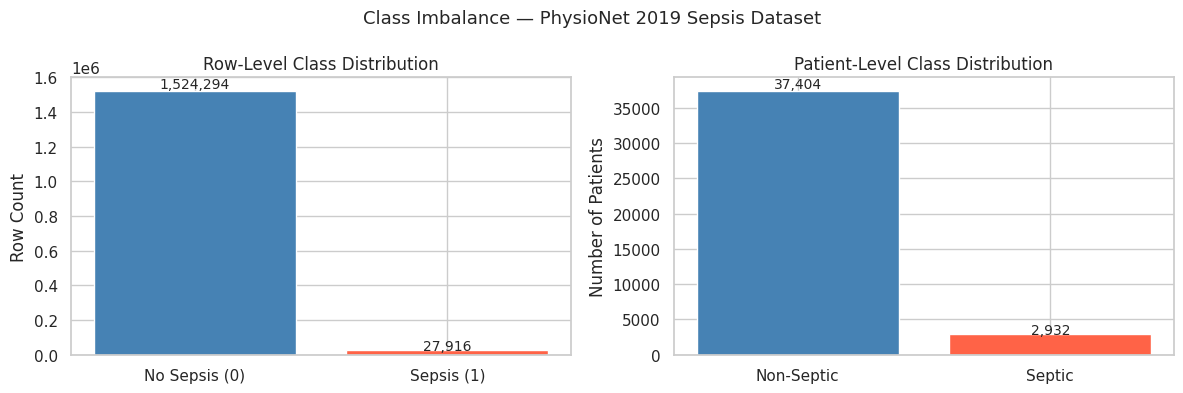

In [ ]:
# ── Row-level label distribution ───────────────────────────────────────────────
row_dist = df['SepsisLabel'].value_counts()
row_pct  = df['SepsisLabel'].value_counts(normalize=True).mul(100).round(2)

print('=== Row-Level Label Distribution ===')
print(pd.DataFrame({'count': row_dist, 'pct (%)': row_pct}))

# ── Patient-level label distribution ──────────────────────────────────────────
# A patient is classified as septic if they have at least one SepsisLabel=1 row.
patient_label = df.groupby('Patient_ID')['SepsisLabel'].max()
pat_dist = patient_label.value_counts()
pat_pct  = patient_label.value_counts(normalize=True).mul(100).round(2)

print('\n=== Patient-Level Label Distribution ===')
print(pd.DataFrame({'count': pat_dist, 'pct (%)': pat_pct}))

# ── Visual ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['No Sepsis (0)', 'Sepsis (1)'], row_dist.values,
            color=['steelblue', 'tomato'], edgecolor='white')
axes[0].set_title('Row-Level Class Distribution')
axes[0].set_ylabel('Row Count')
for i, v in enumerate(row_dist.values):
    axes[0].text(i, v * 1.01, f'{v:,}', ha='center', fontsize=10)

axes[1].bar(['Non-Septic', 'Septic'], pat_dist.values,
            color=['steelblue', 'tomato'], edgecolor='white')
axes[1].set_title('Patient-Level Class Distribution')
axes[1].set_ylabel('Number of Patients')
for i, v in enumerate(pat_dist.values):
    axes[1].text(i, v * 1.01, f'{v:,}', ha='center', fontsize=10)

plt.suptitle('Class Imbalance — PhysioNet 2019 Sepsis Dataset', fontsize=13)
plt.tight_layout()
plt.show()

## Summary of Key Findings
*(Based on exploratory data analysis)*

---

### 1. Lab Test Features
**Finding**

Most lab columns (Bilirubin_direct, Fibrinogen, TroponinI, Lactate, etc.) contain **>80% missing values**, well beyond the red threshold line.

**Implication for Preprocessing**

These are **clinically ordered lab tests**, not continuously recorded sensor data, so missingness is expected.  
We will:
- Apply **forward-fill (LOCF)** per patient
- Use **median imputation** for remaining NaNs  
These columns will **not be dropped**, since **Lactate is an important sepsis biomarker**.

---

### 2. Vital Signs
**Finding**

Vital signs (HR, MAP, O2Sat, SBP, Resp, DBP) have **low missingness (~10–30%)**, all below the 50% threshold.

**Implication for Preprocessing**

Vital signs are **reliably recorded ICU measurements**.  
Small gaps can be handled using **forward-fill imputation**.

---

### 3. Temperature Outliers
**Finding**

Six temperature values fall outside the **25–45°C clinical range**.

**Implication for Preprocessing**

These values likely represent **data entry errors**.  
They will be handled by:
- **Clipping to valid ranges**, or
- **Replacing with NaN and imputing**

---

### 4. Dataset Integrity
**Finding**

- No duplicate rows detected  
- `ICULOS` ranges from **1 to 336 hours**  
- Median patient stay: **38 hours**  
- Minimum stay: **8 hours**

**Implication for Preprocessing**

The dataset structure is **consistent and reliable**.  
However, the **8-hour minimum stay** is important because sequences shorter than the prediction window require careful handling during **time-series sequence generation**.

---

---
## Next Steps — `II_preprocessing.ipynb`

1. Subset dataframe to the 17 selected features
2. Patient-wise train/test split (80/20) — **never row-wise, always patient-wise**
3. Forward-fill missing values per patient (LOCF — Last Observation Carried Forward)
4. Median imputation for any remaining NaNs after forward-fill
5. StandardScaler fit on train set only, then applied to both train and test sets